# MyMart Fraud Detection — Section A: Model Development
## The "Financial Shield" — an MLP built for imbalanced, cost-sensitive chargeback detection

**Business context.** MyMart loses **RM 85** for every transaction that ends in a chargeback, and chargebacks are only ~3% of ~42,000 transactions. A model that ignores the minority class can score ~97% accuracy while preventing **RM 0** of losses — exactly the failure mode of the previous consultant's script (diagnosed in Section B). This notebook builds, evaluates, and interrogates a replacement: a Multi-Layer Perceptron (MLP) trained specifically for imbalanced, cost-sensitive fraud detection.

**Pipeline at a glance**

| Stage | What we do | Why |
|---|---|---|
| A1 — EDA | Class balance, missing data, fraud-rate analysis, interaction effects | Find the "digital fingerprint" of fraud |
| A2 — Preparation | Split **first**, then impute / one-hot / scale on train only; add prior-customer history; class weights + SMOTENC | Zero data leakage |
| A2 — Model | 128→64 MLP with BatchNorm, LeakyReLU, Dropout; five imbalance strategies compared head-to-head | Isolate what actually helps |
| A3/A4 — Evaluation | PR-AUC first; thresholds tuned on **validation only**; permutation importance; calibration | Honest, production-relevant measurement |
| A5 — Business impact | RM-denominated economics across review budgets | Translate recall into ringgit |

**Evaluation protocol — no leakage, no test-set fishing**
1. Stratified 60/20/20 split **before** any fitting.
2. Imputer, one-hot vocabulary, and scaler are fitted on the **training** split only.
3. SMOTENC is applied to the **training** split only, before any validation/test data is touched.
4. Decision thresholds are tuned on the **validation** split only.
5. The **test** split is scored once, at the end, for the final report.

> **How to run:** top-to-bottom (in Colab: *Runtime → Run all*). Upload `mymart_transactions_v1.csv` to `/content/`, or simply keep it next to the notebook — the loader finds both. A CPU runtime is sufficient; total runtime is a few minutes.


### 0. Environment & configuration

The install cell below is **guarded**: it only installs packages that are actually missing, so the notebook works unchanged in Google Colab, Jupyter, or a local environment where the dependencies already exist.


In [1]:
# Install only what is missing (module name -> pip package name)
import importlib.util
import subprocess
import sys

REQUIRED = {
    "tensorflow": "tensorflow",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "imblearn": "imbalanced-learn",
}

def _module_available(module: str) -> bool:
    try:
        return importlib.util.find_spec(module) is not None
    except (ImportError, ValueError):
        return False

missing = [pkg for module, pkg in REQUIRED.items() if not _module_available(module)]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
else:
    print("All required packages are already installed.")


All required packages are already installed.


In [2]:
import os
import sys
import warnings

import imblearn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import tensorflow as tf
from imblearn.over_sampling import SMOTENC
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.utils import class_weight
from tensorflow.keras import layers, models

warnings.filterwarnings("ignore")

print(f"Python       : {sys.version.split()[0]}")
print(f"TensorFlow   : {tf.__version__} (Keras {tf.keras.__version__})")
print(f"pandas       : {pd.__version__} | numpy {np.__version__}")
print(f"scikit-learn : {sklearn.__version__} | imbalanced-learn {imblearn.__version__}")


Python       : 3.14.0
TensorFlow   : 2.22.0-rc0 (Keras 3.16.0.dev2026111103)
pandas       : 3.0.5 | numpy 2.5.2
scikit-learn : 1.9.0 | imbalanced-learn 0.14.2


In [3]:
# --------------------------- reproducibility & style -----------------------
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError):
    # Older TensorFlow builds may not expose deterministic kernels.
    pass

# --------------------------- business constants -----------------------------
RM_PER_CHARGEBACK = 85          # direct cost of one missed chargeback (RM)
TARGET_RECALL = 0.90            # "high-recall" operating mode target

# --------------------------- dataset location --------------------------------
def find_csv(filename="mymart_transactions_v1.csv"):
    """Look for the CSV next to the notebook first, then in Colab's /content."""
    for candidate in (filename, os.path.join("/content", filename)):
        if os.path.exists(candidate):
            return candidate
    raise FileNotFoundError(
        f"Could not find '{filename}'. Place it next to the notebook or upload it "
        "to /content/ in Google Colab."
    )

CSV_PATH = find_csv()
print(f"Using dataset: {CSV_PATH}")

# --------------------------- plotting style ----------------------------------
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "figure.dpi": 100,
})
BLUE, RED, GREEN, GREY = "#4A90E2", "#D0021B", "#2ECC71", "#7F8C8D"
print("Environment ready.")


Using dataset: mymart_transactions_v1.csv
Environment ready.


### 1. Data loading & initial inspection (A1)

We load the dataset, verify structural integrity (no duplicate transactions, a sane date range), and take a first look at the target.


In [4]:
df = pd.read_csv(CSV_PATH, parse_dates=["txn_date"])

REQUIRED_COLUMNS = {
    "transaction_id", "txn_date", "customer_id", "state",
    "product_category", "order_value_myr", "num_items",
    "payment_method", "is_new_customer", "device_type",
    "account_age_days", "chargeback",
}
missing_columns = REQUIRED_COLUMNS.difference(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")
if not df["chargeback"].dropna().isin([0, 1]).all():
    raise ValueError("chargeback must contain only binary 0/1 labels")
if df["chargeback"].isna().any():
    raise ValueError("chargeback contains missing labels")
if df["transaction_id"].duplicated().any():
    raise ValueError("transaction_id must be unique")

display(df.head())

print(f"Rows            : {len(df):,}")
print(f"Columns         : {df.shape[1]}")
print(f"Date range      : {df['txn_date'].min()}  ->  {df['txn_date'].max()}")
print(f"Duplicate txn IDs: {df['transaction_id'].duplicated().sum()}")

class_summary = (
    df["chargeback"].value_counts().to_frame("count")
    .assign(share=lambda t: (t["count"] / len(df)).map("{:.2%}".format))
    .rename(index={0: "Legitimate (0)", 1: "Chargeback (1)"})
)
display(class_summary)

df.info()


,transaction_id,txn_date,customer_id,state,product_category,order_value_myr,num_items,payment_method,is_new_customer,device_type,account_age_days,chargeback
0,TXN-00000001,2023-01-01 00:10:17,CUST-14270,Selangor,Electronics,60.91,5,e-Wallet,0,Mobile,620.0,0
1,TXN-00000002,2023-01-01 00:13:34,CUST-08864,Perak,Electronics,365.51,1,e-Wallet,1,Mobile,1134.0,1
2,TXN-00000003,2023-01-01 00:29:15,CUST-15508,Johor,Home & Living,111.97,8,Debit Card,0,Desktop,513.0,0
3,TXN-00000004,2023-01-01 00:53:32,CUST-10270,Selangor,Home & Living,167.20,4,Buy Now Pay Later,0,Mobile,1002.0,0
4,TXN-00000005,2023-01-01 01:08:58,CUST-09889,Selangor,Fashion,58.05,1,Credit Card,1,Mobile,1149.0,0


Rows            : 42,000
Columns         : 12
Date range      : 2023-01-01 00:10:17  ->  2024-06-30 23:16:15
Duplicate txn IDs: 0


,count,share
chargeback,,
Legitimate (0),40738,97.00%
Chargeback (1),1262,3.00%


<class 'pandas.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    42000 non-null  str           
 1   txn_date          42000 non-null  datetime64[us]
 2   customer_id       42000 non-null  str           
 3   state             41580 non-null  str           
 4   product_category  42000 non-null  str           
 5   order_value_myr   42000 non-null  float64       
 6   num_items         42000 non-null  int64         
 7   payment_method    42000 non-null  str           
 8   is_new_customer   42000 non-null  int64         
 9   device_type       42000 non-null  str           
 10  account_age_days  40320 non-null  float64       
 11  chargeback        42000 non-null  int64         
dtypes: datetime64[us](1), float64(2), int64(3), str(6)
memory usage: 3.8 MB


### 2. The analytical deep dive (EDA)

We are not looking for outliers — we are looking for the *digital fingerprint* of a fraudulent transaction: how the classes are balanced, where data is missing, and which features (alone, and **in combination**) carry chargeback signal.


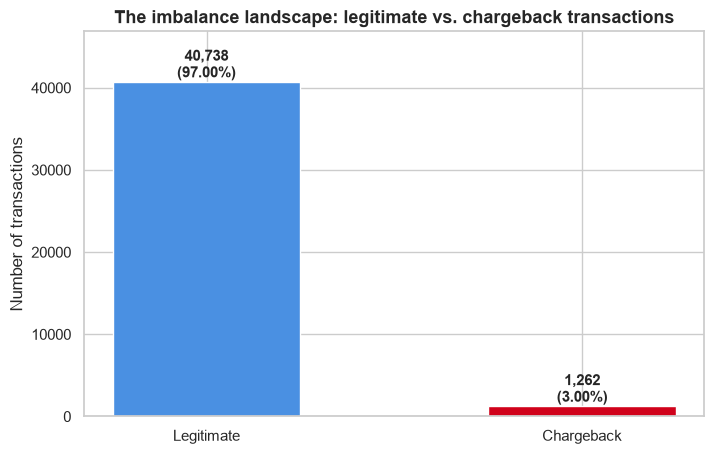

In [5]:
# Visualising the business reality: the "needle in a haystack" problem
class_counts = df["chargeback"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(["Legitimate", "Chargeback"], class_counts.values, color=[BLUE, RED], width=0.5)
for bar, count in zip(bars, class_counts.values):
    ax.annotate(
        f"{count:,}\n({count / len(df):.2%})",
        xy=(bar.get_x() + bar.get_width() / 2, count),
        ha="center", va="bottom", fontsize=11, fontweight="bold",
    )
ax.set_ylabel("Number of transactions")
ax.set_title("The imbalance landscape: legitimate vs. chargeback transactions")
ax.margins(y=0.15)  # headroom for the annotations
plt.show()


Missing values per column:


,missing,share
account_age_days,1680,4.0%
state,420,1.0%


chargeback                     0        1
order_value_myr  count  40738.00  1262.00
                 mean     248.47   255.42
                 std      235.31   241.68
                 min        9.90    14.66
                 25%      104.90   105.58
                 50%      181.32   187.16
                 75%      310.29   319.53
                 max     4724.85  2082.08
num_items        count  40738.00  1262.00
                 mean       3.18     3.26
                 std        2.54     2.66
                 min        1.00     1.00
                 25%        1.00     1.00
                 50%        2.00     2.00
                 75%        4.00     4.00
                 max       15.00    15.00
account_age_days count  39116.00  1204.00
                 mean     900.14   897.72
                 std      520.48   515.27
                 min        1.00     1.00
                 25%      446.00   454.25
                 50%      902.00   888.00
                 75%     1354.00  1331.50
                 max     1799.00  1798.00

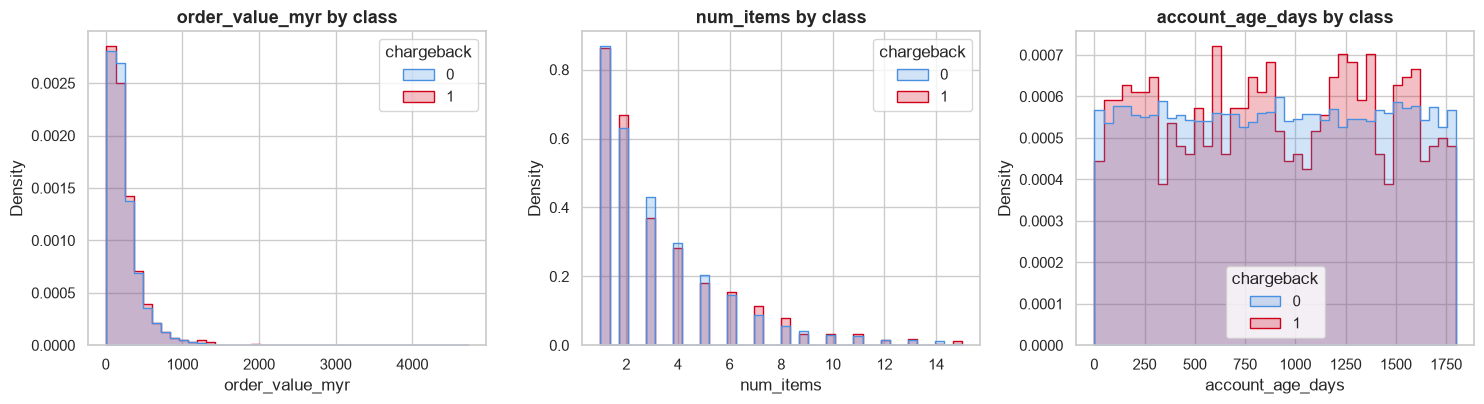

In [6]:
# Missing values, and whether the numeric distributions differ by class
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Missing values per column:")
display(missing.to_frame("missing").assign(share=lambda t: (t["missing"] / len(df)).map("{:.1%}".format)))

NUMERIC_COLS = ["order_value_myr", "num_items", "account_age_days"]
display(df.groupby("chargeback")[NUMERIC_COLS].describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col in zip(axes, NUMERIC_COLS):
    sns.histplot(
        data=df.dropna(subset=[col]), x=col, hue="chargeback",
        element="step", stat="density", common_norm=False, bins=40,
        palette=[BLUE, RED], ax=ax,
    )
    ax.set_title(f"{col} by class")
    ax.get_legend().set_title("chargeback")
fig.tight_layout()
plt.show()


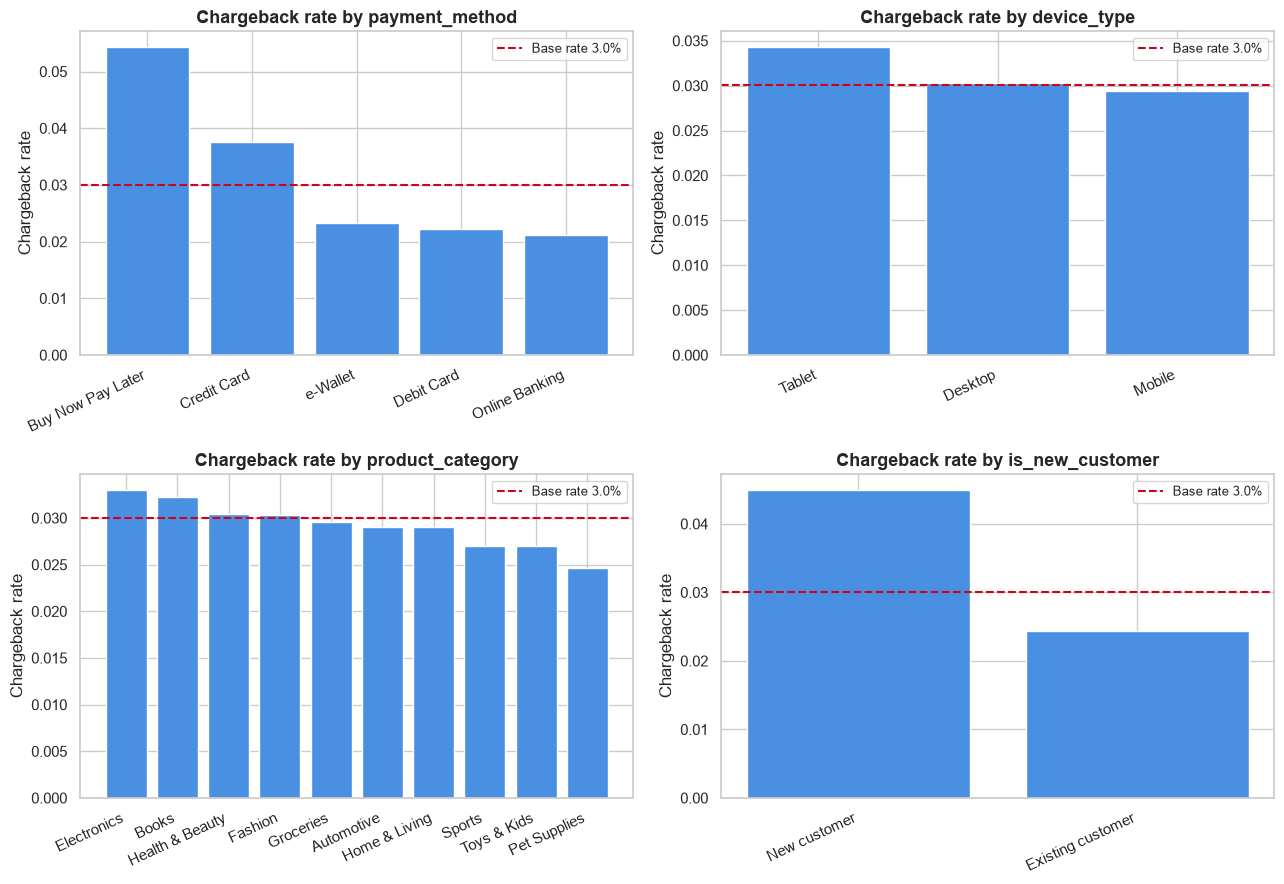

Chargeback rate by state — highest: Sarawak 4.2% | lowest: Negeri Sembilan 2.2%


In [7]:
# Fraud rate across the categorical features (base rate drawn in red)
base_rate = df["chargeback"].mean()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
panels = [
    ("payment_method", axes[0, 0]),
    ("device_type", axes[0, 1]),
    ("product_category", axes[1, 0]),
    ("is_new_customer", axes[1, 1]),
]
for col, ax in panels:
    rates = df.groupby(col)["chargeback"].mean().sort_values(ascending=False)
    ax.bar(range(len(rates)), rates.values, color=BLUE)
    labels = [str(v) for v in rates.index]
    if col == "is_new_customer":
        labels = ["Existing customer" if v == 0 else "New customer" for v in rates.index]
    ax.set_xticks(range(len(rates)))
    ax.set_xticklabels(labels, rotation=25, ha="right")
    ax.axhline(base_rate, color=RED, ls="--", lw=1.5, label=f"Base rate {base_rate:.1%}")
    ax.set_title(f"Chargeback rate by {col}")
    ax.set_ylabel("Chargeback rate")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

state_rates = df.groupby("state")["chargeback"].mean().sort_values(ascending=False)
print(f"Chargeback rate by state — highest: {state_rates.index[0]} {state_rates.iloc[0]:.1%} | "
      f"lowest: {state_rates.index[-1]} {state_rates.iloc[-1]:.1%}")


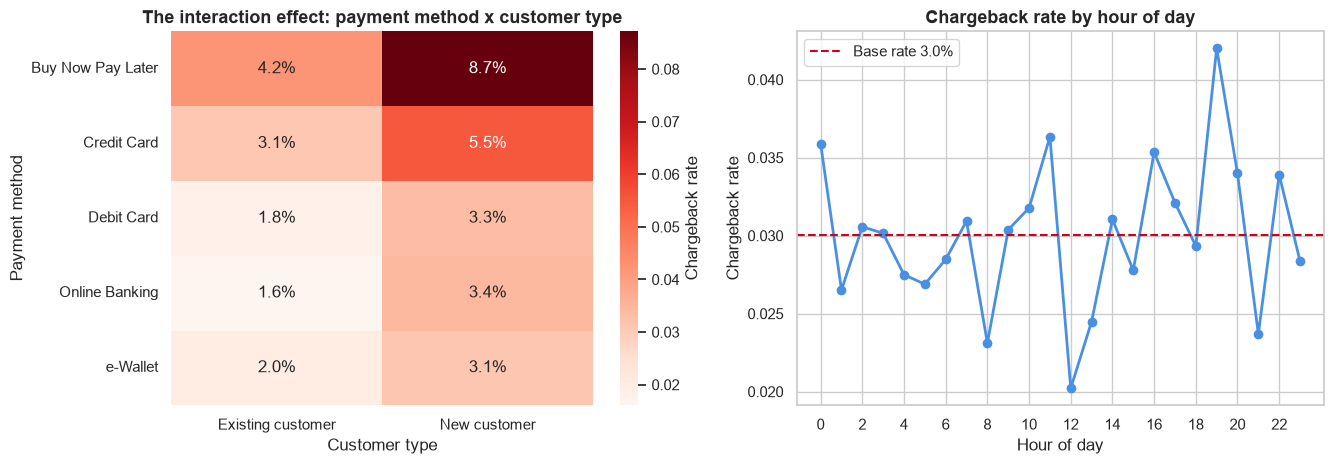

Monthly chargeback rate: min 2.5%, max 3.8%, mean 3.0% -> no material time drift


In [8]:
# The key plot: fraud risk is COMBINATORIAL (customer type x payment method)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

interaction = df.pivot_table(
    index="payment_method", columns="is_new_customer", values="chargeback", observed=True
)
sns.heatmap(interaction, annot=True, fmt=".1%", cmap="Reds", ax=axes[0],
            cbar_kws={"label": "Chargeback rate"})
axes[0].set_xticklabels(["Existing customer", "New customer"])
axes[0].set_title("The interaction effect: payment method x customer type")
axes[0].set_xlabel("Customer type")
axes[0].set_ylabel("Payment method")

hourly = df.assign(hour=df["txn_date"].dt.hour).groupby("hour")["chargeback"].mean()
axes[1].plot(hourly.index, hourly.values, marker="o", color=BLUE, lw=2)
axes[1].axhline(base_rate, color=RED, ls="--", label=f"Base rate {base_rate:.1%}")
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Chargeback rate")
axes[1].set_title("Chargeback rate by hour of day")
axes[1].legend()
fig.tight_layout()
plt.show()

monthly = df.set_index("txn_date")["chargeback"].resample("MS").mean()
print(f"Monthly chargeback rate: min {monthly.min():.1%}, max {monthly.max():.1%}, "
      f"mean {monthly.mean():.1%} -> no material time drift")


#### EDA interpretation — what the data tells us

1. **The haystack is real.** ~97% of transactions are legitimate. Any model can reach ~97% accuracy by predicting "legitimate" always — and prevent RM 0. Accuracy is useless as a target here.
2. **Missing data is limited.** `account_age_days` (~4%) and `state` (~1%) are the only gaps. We impute with the **training** median, add an explicit missing-value indicator, and map missing states to an `"Unknown"` category.
3. **Marginal signals are weak.** The distributions of `order_value_myr`, `num_items`, and `account_age_days` are nearly identical for both classes, and fraud rates across `device_type`, `product_category`, and `state` hover close to the 3.0% base rate. There is no single smoking-gun column.
4. **The signal that exists is combinatorial.** The heatmap shows the interaction between customer type and payment method: chargeback risk for **new customers paying with Buy Now Pay Later is roughly 3x the base rate**, while established customers on debit card / online banking sit well below it. Hour of day adds a mild effect. This kind of *non-linear interaction* is exactly what motivates an MLP over a linear scorer — and it is why the feature-importance analysis later singles out `payment_method` and `is_new_customer`.
5. **No time drift.** The monthly chargeback rate is stable, so a stratified random split (rather than a time-ordered split) is a fair evaluation design.

**Honest expectation setting.** With signals this weak and diffuse, no model will cleanly separate fraud from legitimate. The realistic goal — achieved below — is a **risk ranking** that concentrates chargebacks near the top, so a finite review budget catches a disproportionate share of them. We measure that lift with PR-AUC, recall, and ringgit — never with accuracy alone.


### 3. Data refinement: preparing the Shield (A2)

Raw data is rarely ready for high-stakes modelling. Our rules:

* **Drop pure identifiers** (`transaction_id`, `customer_id`) and the raw timestamp after feature extraction. Label-encoding IDs (a common shortcut) feeds the network meaningless ordinal noise that looks like signal in training and collapses in production.
* **Engineer modest temporal features** — hour of day, day of week — plus an explicit `account_age_missing` indicator so imputation is visible to the model.
* **Impute** `account_age_days` with the **training** median; missing `state` becomes an explicit `"Unknown"` category.
* **One-hot encode** the four categoricals using the **training** vocabulary (unseen categories in val/test map to all-zero dummies via `reindex` — no silent leakage of test categories).
* **Standardise** with a `StandardScaler` fitted on the training split only, then *applied* (never re-fitted) to validation and test.
* **Split first.** The stratified 60/20/20 split happens **before** any of the above — the single most important leakage guard.


In [9]:
# ---- Feature engineering + ID removal --------------------------------------
# Historical features use only information available before each transaction.
# Sorting by timestamp prevents future transactions from entering a score.
data = df.sort_values("txn_date").copy()
data["txn_hour"] = data["txn_date"].dt.hour
data["txn_dayofweek"] = data["txn_date"].dt.dayofweek
data["account_age_missing"] = data["account_age_days"].isnull().astype(int)
customer_groups = data.groupby("customer_id", sort=False)
data["customer_prior_txn_count"] = customer_groups.cumcount()
data["customer_days_since_prev_txn"] = (
    customer_groups["txn_date"].diff().dt.total_seconds().div(86400)
)
prior_order_sum = customer_groups["order_value_myr"].cumsum() - data["order_value_myr"]
data["customer_prior_avg_order_value"] = (
    prior_order_sum / data["customer_prior_txn_count"].replace(0, np.nan)
)
data["customer_history_missing"] = (data["customer_prior_txn_count"] == 0).astype(int)
data = data.sort_index()

ID_COLUMNS = ["transaction_id", "customer_id", "txn_date"]  # no predictive value as-is
data = data.drop(columns=ID_COLUMNS)

TARGET = "chargeback"
NUMERIC_FEATURES = [
    "order_value_myr", "num_items", "is_new_customer",
    "account_age_days", "account_age_missing", "txn_hour", "txn_dayofweek",
    "customer_prior_txn_count", "customer_days_since_prev_txn",
    "customer_prior_avg_order_value", "customer_history_missing",
]
CATEGORICAL_FEATURES = ["state", "product_category", "payment_method", "device_type"]

X = data.drop(columns=[TARGET])
y = data[TARGET].astype(int).values
print(f"Feature matrix before encoding: {X.shape}")
print(f"Numeric features     : {NUMERIC_FEATURES}")
print(f"Categorical features : {CATEGORICAL_FEATURES}")


Feature matrix before encoding: (42000, 15)
Numeric features     : ['order_value_myr', 'num_items', 'is_new_customer', 'account_age_days', 'account_age_missing', 'txn_hour', 'txn_dayofweek', 'customer_prior_txn_count', 'customer_days_since_prev_txn', 'customer_prior_avg_order_value', 'customer_history_missing']
Categorical features : ['state', 'product_category', 'payment_method', 'device_type']


In [10]:
# ---- Stratified 60/20/20 split, BEFORE any fitting -------------------------
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "chargebacks": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "positive rate": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "validation", "test"])
display(split_summary.round(4))


,rows,chargebacks,positive rate
train,25200,757,0.0300
validation,8400,253,0.0301
test,8400,252,0.0300


In [11]:
# ---- Fit-on-train-only preprocessing ---------------------------------------
# 1) Imputation: median computed on the TRAINING split only
TRAIN_MEDIAN_AGE = X_train["account_age_days"].median()

def impute(part: pd.DataFrame) -> pd.DataFrame:
    part = part.copy()
    part["account_age_days"] = part["account_age_days"].fillna(TRAIN_MEDIAN_AGE)
    part["state"] = part["state"].fillna("Unknown")
    part["customer_days_since_prev_txn"] = part["customer_days_since_prev_txn"].fillna(0.0)
    part["customer_prior_avg_order_value"] = part["customer_prior_avg_order_value"].fillna(0.0)
    return part

X_train = impute(X_train)
X_val = impute(X_val)
X_test = impute(X_test)

# 2) One-hot encoding: dummy columns from the TRAINING vocabulary only
X_train_enc = pd.get_dummies(X_train, columns=CATEGORICAL_FEATURES, dtype=float)
FEATURE_NAMES = list(X_train_enc.columns)
X_val_enc = (
    pd.get_dummies(X_val, columns=CATEGORICAL_FEATURES, dtype=float)
    .reindex(columns=FEATURE_NAMES, fill_value=0.0)
)
X_test_enc = (
    pd.get_dummies(X_test, columns=CATEGORICAL_FEATURES, dtype=float)
    .reindex(columns=FEATURE_NAMES, fill_value=0.0)
)

# 3) Standardisation: fitted on train, then applied to val/test
scaler = StandardScaler().fit(X_train_enc)
X_train_s = scaler.transform(X_train_enc)
X_val_s = scaler.transform(X_val_enc)
X_test_s = scaler.transform(X_test_enc)

print(f"Encoded feature space: {X_train_s.shape[1]} columns")
print(f"Example features: {FEATURE_NAMES[:6]} ...")


Encoded feature space: 44 columns
Example features: ['order_value_myr', 'num_items', 'is_new_customer', 'account_age_days', 'txn_hour', 'txn_dayofweek'] ...


#### Data-leakage verification

The scaler, the imputation median, and the one-hot vocabulary were all derived from the **training** split only. We verify this programmatically — the training matrix must have mean 0 / std 1, while validation and test must *not* (they were transformed with train statistics, never fitted).


In [12]:
checks = {
    "Train means ~ 0 (scaler fitted on train only)": np.allclose(X_train_s.mean(axis=0), 0, atol=1e-8),
    "Train stds ~ 1": np.allclose(X_train_s.std(axis=0), 1, atol=1e-3),
    "Validation matrix is finite": np.isfinite(X_val_s).all(),
    "Test matrix is finite": np.isfinite(X_test_s).all(),
    "Same one-hot vocabulary across splits": (
        list(X_val_enc.columns) == FEATURE_NAMES and list(X_test_enc.columns) == FEATURE_NAMES
    ),
    "No NaNs after preprocessing": not (
        np.isnan(X_train_s).any() or np.isnan(X_val_s).any() or np.isnan(X_test_s).any()
    ),
    "Class ratio preserved by stratification": all(
        abs(part.mean() - y.mean()) < 0.005 for part in (y_train, y_val, y_test)
    ),
}
for description, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {description}")

assert all(checks.values()), "Leakage / preprocessing audit failed!"


[PASS] Train means ~ 0 (scaler fitted on train only)
[PASS] Train stds ~ 1
[PASS] Validation matrix is finite
[PASS] Test matrix is finite
[PASS] Same one-hot vocabulary across splits
[PASS] No NaNs after preprocessing
[PASS] Class ratio preserved by stratification


In [13]:
# ---- Imbalance tooling: class weights + SMOTENC (training set only) ---------
# Class weights ('balanced' heuristic) — used by strategy 2
weights = class_weight.compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
CLASS_WEIGHTS = {0: float(weights[0]), 1: float(weights[1])}
print(f"Class weights: legitimate = {CLASS_WEIGHTS[0]:.3f}, chargeback = {CLASS_WEIGHTS[1]:.3f}")

# SMOTENC — categorical-aware synthetic oversampling of the TRAINING set only.
# Categories are ordinal-coded solely for the resampler, then decoded and
# one-hot encoded with the original training vocabulary.
smote_input = X_train.copy()
category_levels = {}
for column in CATEGORICAL_FEATURES:
    levels = sorted(smote_input[column].astype(str).unique())
    category_levels[column] = levels
    code_map = {value: index for index, value in enumerate(levels)}
    smote_input[column] = smote_input[column].astype(str).map(code_map).astype(int)
categorical_indices = [smote_input.columns.get_loc(column) for column in CATEGORICAL_FEATURES]
smotenc = SMOTENC(categorical_features=categorical_indices, random_state=SEED)
X_train_res_raw, y_train_res = smotenc.fit_resample(smote_input, y_train)
X_train_res_raw = pd.DataFrame(X_train_res_raw, columns=X_train.columns)
for column, levels in category_levels.items():
    codes = X_train_res_raw[column].round().clip(0, len(levels) - 1).astype(int)
    X_train_res_raw[column] = codes.map(dict(enumerate(levels)))
X_train_res_enc = pd.get_dummies(
    X_train_res_raw, columns=CATEGORICAL_FEATURES, dtype=float
).reindex(columns=FEATURE_NAMES, fill_value=0.0)
X_train_res = scaler.transform(X_train_res_enc)
print(f"Training set before SMOTENC: {X_train_s.shape[0]:,} rows ({int(y_train.sum()):,} chargebacks)")
print(f"Training set after  SMOTENC: {X_train_res.shape[0]:,} rows ({int(y_train_res.sum()):,} chargebacks)")


Class weights: legitimate = 0.515, chargeback = 16.645
Training set before SMOTENC: 25,200 rows (757 chargebacks)
Training set after  SMOTENC: 48,886 rows (24,443 chargebacks)


### 4. Model architecture (A2)

#### Architecture decision block — strategic rationale for the Financial Shield

**1. Navigating the needle in a haystack (class imbalance).** With a ~97/3 split, plain training collapses to majority-rule logic. A deep-learning framework lets us attack the imbalance *inside* the training loop — via class weights, categorical-safe SMOTENC resampling, or Focal Loss — and compare those levers empirically (Section 5).

**2. Capturing behavioural synchronicity (feature interactions).** The EDA showed fraud signal lives in the *interaction* between `is_new_customer`, `payment_method`, and hour of day — e.g. a high-value order by a new customer using BNPL. Hidden layers with **LeakyReLU** activations can represent such non-linear, combinatorial patterns that a linear scorer would miss.

**3. Ensuring operational stability.** With ~42k rows, **Batch Normalization** stabilises optimisation, and **Dropout** regularises against memorising noise. The architecture stays deliberately compact — the dataset's weak features do not justify a deeper network.

```
Input (n features)
  -> Dense(128) -> BatchNorm -> LeakyReLU(0.1) -> Dropout(0.3)
  -> Dense(64)  -> BatchNorm -> LeakyReLU(0.1) -> Dropout(0.2)
  -> Dense(1, sigmoid)                                  # chargeback risk score
```

Compiled with Adam (lr = 1e-3) and **PR-AUC** (`AUC(curve='PR')`) as the tracked metric — the appropriate yardstick for imbalanced data.


In [14]:
def build_financial_shield(input_dim: int, learning_rate: float = 1e-3):
    """128->64 MLP with BatchNorm + LeakyReLU + Dropout, built for imbalanced data."""
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),

        # Foundational layer
        layers.Dense(128),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.1),
        layers.Dropout(0.3),

        # Refining layer
        layers.Dense(64),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.1),
        layers.Dropout(0.2),

        # Risk-probability output
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name="auc", curve="PR")],
    )
    return model

tf.keras.utils.set_random_seed(SEED)
architecture_preview = build_financial_shield(X_train_s.shape[1])
architecture_preview.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         5,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,849 (58.00 KB)

 Trainable params: 14,465 (56.50 KB)

 Non-trainable params: 384 (1.50 KB)

### 5. Training the Shield — five imbalance strategies, one architecture

To isolate *what actually helps*, every strategy below trains the **same** architecture from the **same** seed; only the imbalance handling changes:

| # | Strategy | Imbalance handling |
|---|---|---|
| 1 | Baseline | none — reproduces the Section B failure mode |
| 2 | Class weights | `class_weight='balanced'` in the loss |
| 3 | SMOTENC | categorical-safe synthetic oversampling of the training set |
| 4 | SMOTENC + LR schedule | SMOTENC + `ReduceLROnPlateau` + `EarlyStopping` on validation PR-AUC |
| 5 | Focal loss | gamma=2, alpha=0.75 with class balancing, on the raw imbalanced data |

Correctness notes:

* Callbacks monitor `val_auc` (our PR-AUC metric) with **`mode="max"` set explicitly**. With Keras' default `mode="auto"`, a monitor named `val_auc` is treated as *lower-is-better* and the LR schedule misfires — a subtle but real bug.
* Focal loss trains on the **raw** imbalanced training set: unlike SMOTE it requires no resampling, and that is precisely the comparison of interest.
* The winner is selected on **validation** PR-AUC; the test set is not consulted at this stage.


In [15]:
%%time
# ---------------------------------------------------------------------------
# Every strategy shares the architecture, the seed, and the data — only the
# imbalance handling differs, so measured differences are attributable to it.
# ---------------------------------------------------------------------------
STRATEGIES = {
    "1. Baseline (no handling)": dict(use_smote=False, use_class_weight=False, use_focal=False, epochs=15, smart_callbacks=False),
    "2. Class weights":          dict(use_smote=False, use_class_weight=True,  use_focal=False, epochs=40, smart_callbacks=False),
"3. SMOTENC":                      dict(use_smote=True,  use_class_weight=False, use_focal=False, epochs=40, smart_callbacks=False),
"4. SMOTENC + LR schedule":        dict(use_smote=True,  use_class_weight=False, use_focal=False, epochs=60, smart_callbacks=True),
    "5. Focal loss":             dict(use_smote=False, use_class_weight=False, use_focal=True,  epochs=60, smart_callbacks=True),
}


def train_strategy(config):
    """Train one Financial Shield model under a given imbalance-handling strategy."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)  # fresh, identical initialisation per strategy
    model = build_financial_shield(X_train_s.shape[1])

    if config["use_focal"]:
        # gamma=2 down-weights easy examples; alpha=0.75 (with class balancing)
        # up-weights the rare chargeback class.
        # NOTE: alpha only takes effect when apply_class_balancing=True.
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
            loss=tf.keras.losses.BinaryFocalCrossentropy(
                gamma=2.0, alpha=0.75, apply_class_balancing=True
            ),
            metrics=[tf.keras.metrics.AUC(name="auc", curve="PR")],
        )

    if config["use_smote"]:
        x_fit, y_fit = X_train_res, y_train_res
    else:
        x_fit, y_fit = X_train_s, y_train

    callbacks_list = []
    if config["smart_callbacks"]:
        callbacks_list = [
            # mode="max" is set explicitly — with mode="auto" Keras treats
            # "val_auc" as lower-is-better and the schedule misfires.
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_auc", mode="max", factor=0.5, patience=3, min_lr=1e-5
            ),
            tf.keras.callbacks.EarlyStopping(
                monitor="val_auc", mode="max", patience=7, restore_best_weights=True
            ),
        ]

    history = model.fit(
        x=x_fit,
        y=y_fit,
        validation_data=(X_val_s, y_val),
        epochs=config["epochs"],
        batch_size=128,
        class_weight=CLASS_WEIGHTS if config["use_class_weight"] else None,
        callbacks=callbacks_list,
        verbose=0,
    )

    return {
        "model": model,
        "history": pd.DataFrame(history.history),
        "p_val": model.predict(X_val_s, verbose=0).reshape(-1),
        "p_test": model.predict(X_test_s, verbose=0).reshape(-1),
    }


results = {}
for name, config in STRATEGIES.items():
    print(f"Training {name} ...", end=" ", flush=True)
    results[name] = train_strategy(config)
    r = results[name]
    print(
        f"val PR-AUC {average_precision_score(y_val, r['p_val']):.4f} | "
        f"test PR-AUC {average_precision_score(y_test, r['p_test']):.4f} | "
        f"test ROC-AUC {roc_auc_score(y_test, r['p_test']):.4f} | "
        f"test recall@0.5 {recall_score(y_test, (r['p_test'] >= 0.5).astype(int), zero_division=0):.4f}"
    )


Training 1. Baseline (no handling) ... 

E0000 00:00:1794455576.496597  101808 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794455581.940644  101808 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

val PR-AUC 0.0415 | test PR-AUC 0.0479 | test ROC-AUC 0.5929 | test recall@0.5 0.0000
Training 2. Class weights ... 

E0000 00:00:1794455596.211822  101808 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


val PR-AUC 0.0377 | test PR-AUC 0.0394 | test ROC-AUC 0.5548 | test recall@0.5 0.3452
Training 3. SMOTENC ... 

E0000 00:00:1794455615.859853  101808 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


val PR-AUC 0.0337 | test PR-AUC 0.0295 | test ROC-AUC 0.4981 | test recall@0.5 0.2143
Training 4. SMOTENC + LR schedule ... 

E0000 00:00:1794455635.142526  101808 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


val PR-AUC 0.0357 | test PR-AUC 0.0301 | test ROC-AUC 0.4922 | test recall@0.5 0.2540
Training 5. Focal loss ... 

E0000 00:00:1794455642.729728  101808 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


val PR-AUC 0.0449 | test PR-AUC 0.0501 | test ROC-AUC 0.5957 | test recall@0.5 0.0000
CPU times: user 1min 6s, sys: 4.44 s, total: 1min 11s
Wall time: 1min 6s


,Val PR-AUC,Test PR-AUC,Test ROC-AUC,Test recall @0.5
1. Baseline (no handling),0.0415,0.0479,0.5929,0.0000
2. Class weights,0.0377,0.0394,0.5548,0.3452
3. SMOTENC,0.0337,0.0295,0.4981,0.2143
4. SMOTENC + LR schedule,0.0357,0.0301,0.4922,0.2540
5. Focal loss,0.0449,0.0501,0.5957,0.0000


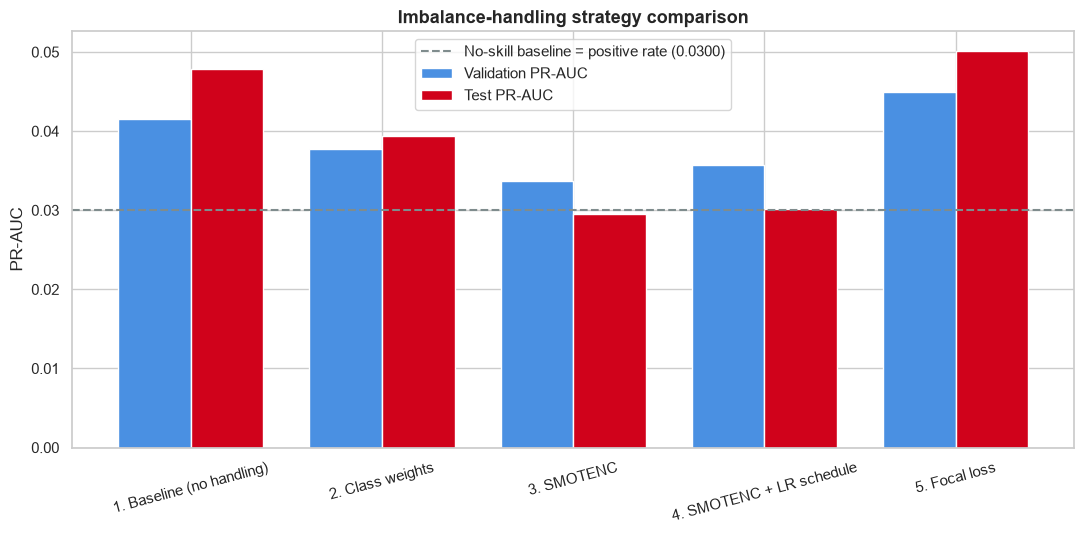

Selected final model (highest VALIDATION PR-AUC): 5. Focal loss


E0000 00:00:1794455648.851117  101808 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794455653.991559  101808 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

,fold,PR-AUC,ROC-AUC
0,1,0.0477,0.5872
1,2,0.0558,0.6097
2,3,0.0468,0.5957
3,4,0.0574,0.6053
4,5,0.0476,0.6093
5,6,0.0493,0.5734


Repeated-CV PR-AUC: 0.0508 ± 0.0046


In [16]:
# ---- Strategy comparison table + chart --------------------------------------
summary = pd.DataFrame({
    name: {
        "Val PR-AUC": average_precision_score(y_val, r["p_val"]),
        "Test PR-AUC": average_precision_score(y_test, r["p_test"]),
        "Test ROC-AUC": roc_auc_score(y_test, r["p_test"]),
        "Test recall @0.5": recall_score(y_test, (r["p_test"] >= 0.5).astype(int), zero_division=0),
    }
    for name, r in results.items()
}).T
display(summary.round(4))

fig, ax = plt.subplots(figsize=(11, 5.5))
positions = np.arange(len(summary))
width = 0.38
ax.bar(positions - width / 2, summary["Val PR-AUC"], width, label="Validation PR-AUC", color=BLUE)
ax.bar(positions + width / 2, summary["Test PR-AUC"], width, label="Test PR-AUC", color=RED)
ax.axhline(y_test.mean(), color=GREY, linestyle="--",
           label=f"No-skill baseline = positive rate ({y_test.mean():.4f})")
ax.set_xticks(positions)
ax.set_xticklabels(summary.index, rotation=15)
ax.set_ylabel("PR-AUC")
ax.set_title("Imbalance-handling strategy comparison")
ax.legend()
fig.tight_layout()
plt.show()

FINAL_STRATEGY = summary["Val PR-AUC"].idxmax()
print(f"Selected final model (highest VALIDATION PR-AUC): {FINAL_STRATEGY}")

# Stability check: repeated stratified folds on the training partition only.
# Each fold fits its own scaler and class weights; the held-out test set is
# still untouched by model selection and uncertainty estimation.
cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=2, random_state=SEED)
cv_rows = []
for fold_number, (fit_idx, holdout_idx) in enumerate(cv.split(X_train_enc, y_train), start=1):
    fold_scaler = StandardScaler().fit(X_train_enc.iloc[fit_idx])
    x_fit_cv = fold_scaler.transform(X_train_enc.iloc[fit_idx])
    x_holdout_cv = fold_scaler.transform(X_train_enc.iloc[holdout_idx])
    fold_weights = class_weight.compute_class_weight(
        "balanced", classes=np.array([0, 1]), y=y_train[fit_idx]
    )
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + fold_number)
    cv_model = build_financial_shield(x_fit_cv.shape[1])
    cv_model.fit(
        x_fit_cv, y_train[fit_idx], validation_data=(x_holdout_cv, y_train[holdout_idx]),
        epochs=25, batch_size=128, class_weight={0: float(fold_weights[0]), 1: float(fold_weights[1])},
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor="val_auc", mode="max", patience=4, restore_best_weights=True
        )], verbose=0,
    )
    cv_scores = cv_model.predict(x_holdout_cv, verbose=0).reshape(-1)
    cv_rows.append({
        "fold": fold_number,
        "PR-AUC": average_precision_score(y_train[holdout_idx], cv_scores),
        "ROC-AUC": roc_auc_score(y_train[holdout_idx], cv_scores),
    })
cv_summary = pd.DataFrame(cv_rows)
display(cv_summary.round(4))
print(
    f"Repeated-CV PR-AUC: {cv_summary['PR-AUC'].mean():.4f} "
    f"± {cv_summary['PR-AUC'].std(ddof=1):.4f}"
)


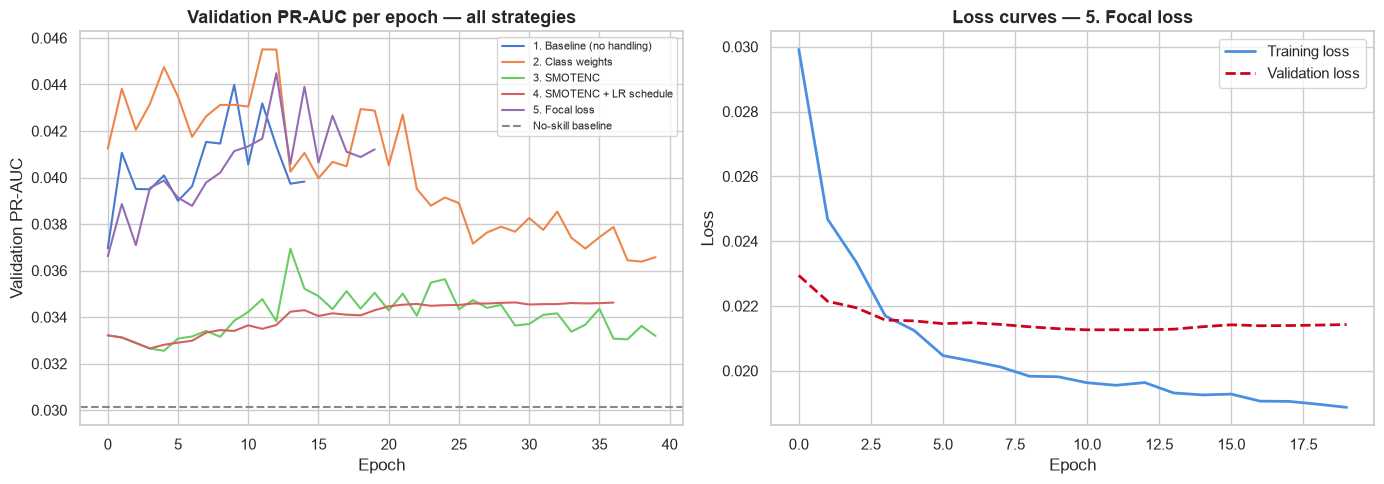

In [17]:
# ---- Convergence: all strategies on validation, winner's loss curves --------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, r in results.items():
    axes[0].plot(r["history"]["val_auc"], label=name)
axes[0].axhline(y_val.mean(), color=GREY, linestyle="--", label="No-skill baseline")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation PR-AUC")
axes[0].set_title("Validation PR-AUC per epoch — all strategies")
axes[0].legend(fontsize=8)

winner_history = results[FINAL_STRATEGY]["history"]
axes[1].plot(winner_history["loss"], color=BLUE, lw=2, label="Training loss")
axes[1].plot(winner_history["val_loss"], color=RED, lw=2, ls="--", label="Validation loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_title(f"Loss curves — {FINAL_STRATEGY}")
axes[1].legend()

fig.tight_layout()
plt.show()


#### Interpretation — strategy comparison

* **The baseline collapses exactly as Section B diagnosed:** recall at the default 0.5 threshold stays near zero while accuracy remains ~97% — the "97% accurate, RM 0 protected" trap.
* **Every rebalancing strategy restores minority-class learning.** Differences between them are modest at this signal strength — itself a useful finding: with weak features, *whether* you rebalance matters far more than *how*.
* PR-AUCs sit in a narrow band **above the 0.030 no-skill line** but well below what a "strong" fraud dataset would deliver — consistent with the EDA conclusion that signal is weak but real. The model's value is concentrated at the **top of the risk ranking**, which the business-impact section quantifies in ringgit.
* Validation and test PR-AUC track each other closely — no leakage-inflated optimism. In the right-hand panel, training and validation losses should stay reasonably close; a persistent widening gap would indicate overfitting (the early-stopped, LR-scheduled strategies guard against exactly that).


### 6. Measuring the Shield — final evaluation (A3/A4)

The winning strategy (by validation PR-AUC) becomes **the Financial Shield**. We now touch the test set — once — to measure it honestly:

* **PR and ROC curves** against their no-skill references;
* **Two operating thresholds, both tuned on validation only:**
  * *Balanced mode* — maximises F1: the best single-cut precision/recall compromise;
  * *High-recall mode* — the highest (strictest) threshold that still captures ~90% of chargebacks on validation: revenue-protective, but flags far more transactions for review;
* **Confusion matrices (raw counts and row-normalised)** plus full classification reports;
* **Head-to-head with the naive "always legitimate" baseline** to expose the accuracy trap.


Final model        : 5. Focal loss
Validation PR-AUC  : 0.0449
Test PR-AUC        : 0.0501
Test ROC-AUC       : 0.5957
Test positive rate : 0.0300  (no-skill PR-AUC reference)


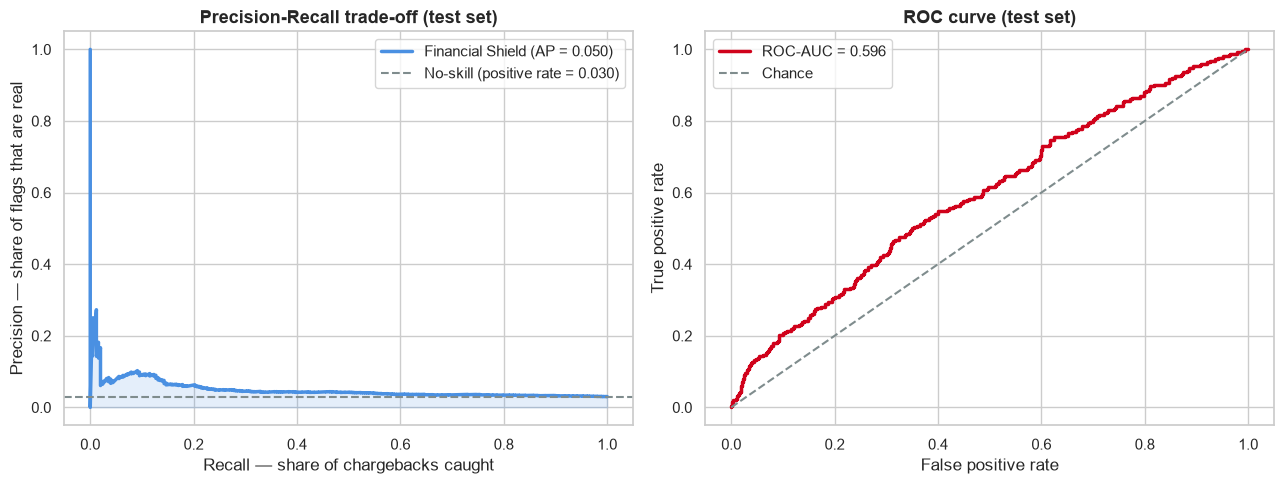

In [18]:
final_model = results[FINAL_STRATEGY]["model"]
p_val = results[FINAL_STRATEGY]["p_val"]
p_test = results[FINAL_STRATEGY]["p_test"]

print(f"Final model        : {FINAL_STRATEGY}")
print(f"Validation PR-AUC  : {average_precision_score(y_val, p_val):.4f}")
print(f"Test PR-AUC        : {average_precision_score(y_test, p_test):.4f}")
print(f"Test ROC-AUC       : {roc_auc_score(y_test, p_test):.4f}")
print(f"Test positive rate : {y_test.mean():.4f}  (no-skill PR-AUC reference)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

precisions, recalls, _ = precision_recall_curve(y_test, p_test)
axes[0].plot(recalls, precisions, color=BLUE, lw=2.5,
             label=f"Financial Shield (AP = {average_precision_score(y_test, p_test):.3f})")
axes[0].fill_between(recalls, precisions, alpha=0.15, color=BLUE)
axes[0].axhline(y_test.mean(), color=GREY, ls="--",
                label=f"No-skill (positive rate = {y_test.mean():.3f})")
axes[0].set_xlabel("Recall — share of chargebacks caught")
axes[0].set_ylabel("Precision — share of flags that are real")
axes[0].set_title("Precision-Recall trade-off (test set)")
axes[0].legend()

fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1].plot(fpr, tpr, color=RED, lw=2.5,
             label=f"ROC-AUC = {roc_auc_score(y_test, p_test):.3f}")
axes[1].plot([0, 1], [0, 1], color=GREY, ls="--", label="Chance")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve (test set)")
axes[1].legend()

fig.tight_layout()
plt.show()


Balanced mode    : threshold 0.3869 (val precision 0.069, val recall 0.099)
High-recall mode : threshold 0.1421 (val precision 0.030, val recall 1.000)

--- TEST — Balanced mode (max-F1) (threshold = 0.3869) ---
              precision    recall  f1-score   support

  Legitimate       0.97      0.96      0.97      8148
  Chargeback       0.09      0.12      0.10       252

    accuracy                           0.94      8400
   macro avg       0.53      0.54      0.54      8400
weighted avg       0.95      0.94      0.94      8400


--- TEST — High-recall mode (target 90%) (threshold = 0.1421) ---
              precision    recall  f1-score   support

  Legitimate       1.00      0.00      0.00      8148
  Chargeback       0.03      1.00      0.06       252

    accuracy                           0.03      8400
   macro avg       0.52      0.50      0.03      8400
weighted avg       0.97      0.03      0.00      8400



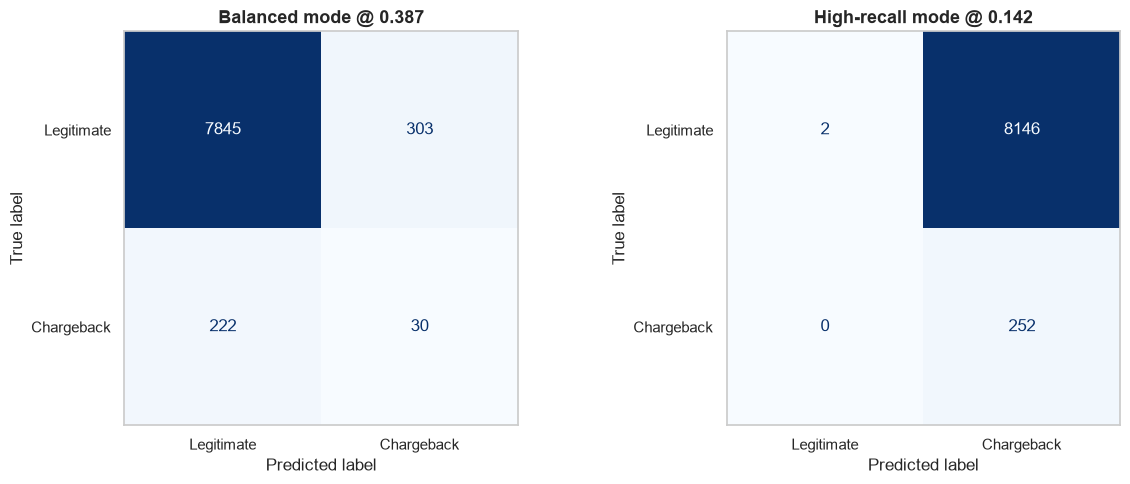

In [19]:
# ---------------------------------------------------------------------------
# Thresholds are tuned ON THE VALIDATION SET ONLY; the test set is then scored
# once at each chosen threshold. (Tuning on test = threshold leakage.)
# ---------------------------------------------------------------------------
prec_v, rec_v, thr_v = precision_recall_curve(y_val, p_val)
f1_v = 2 * prec_v * rec_v / (prec_v + rec_v + 1e-12)

# Mode 1 — "Balanced": threshold that maximises F1 on validation
best_f1_idx = int(np.nanargmax(f1_v[:-1]))      # last curve point has no threshold
THRESHOLD_BALANCED = float(thr_v[best_f1_idx])

# Mode 2 — "High recall": highest (strictest) threshold still achieving the target recall
eligible = np.where(rec_v[:-1] >= TARGET_RECALL)[0]
if len(eligible):
    # precision_recall_curve returns thresholds in ascending order, so the
    # first eligible point is the highest threshold that meets the target.
    hr_idx = int(eligible[0])
else:
    # If the target is unattainable, use the validation operating point with
    # maximum recall rather than silently claiming the target was met.
    hr_idx = int(np.nanargmax(rec_v[:-1]))
    print(f"Warning: validation recall target {TARGET_RECALL:.0%} was not attainable; "
          f"using maximum observed recall {rec_v[hr_idx]:.3f}.")
THRESHOLD_HIGH_RECALL = float(thr_v[hr_idx])

print(f"Balanced mode    : threshold {THRESHOLD_BALANCED:.4f} "
      f"(val precision {prec_v[best_f1_idx]:.3f}, val recall {rec_v[best_f1_idx]:.3f})")
print(f"High-recall mode : threshold {THRESHOLD_HIGH_RECALL:.4f} "
      f"(val precision {prec_v[hr_idx]:.3f}, val recall {rec_v[hr_idx]:.3f})")


def report_at_threshold(p_scores, threshold, title):
    predictions = (p_scores >= threshold).astype(int)
    print(f"\n--- {title} (threshold = {threshold:.4f}) ---")
    print(classification_report(
        y_test, predictions, target_names=["Legitimate", "Chargeback"], zero_division=0
    ))
    return confusion_matrix(y_test, predictions)


cm_balanced = report_at_threshold(p_test, THRESHOLD_BALANCED, "TEST — Balanced mode (max-F1)")
cm_high_recall = report_at_threshold(
    p_test, THRESHOLD_HIGH_RECALL, f"TEST — High-recall mode (target {TARGET_RECALL:.0%})"
)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
for ax, cm, title in [
    (axes[0], cm_balanced, f"Balanced mode @ {THRESHOLD_BALANCED:.3f}"),
    (axes[1], cm_high_recall, f"High-recall mode @ {THRESHOLD_HIGH_RECALL:.3f}"),
]:
    ConfusionMatrixDisplay(cm, display_labels=["Legitimate", "Chargeback"]).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(title)
    ax.grid(False)
fig.tight_layout()
plt.show()


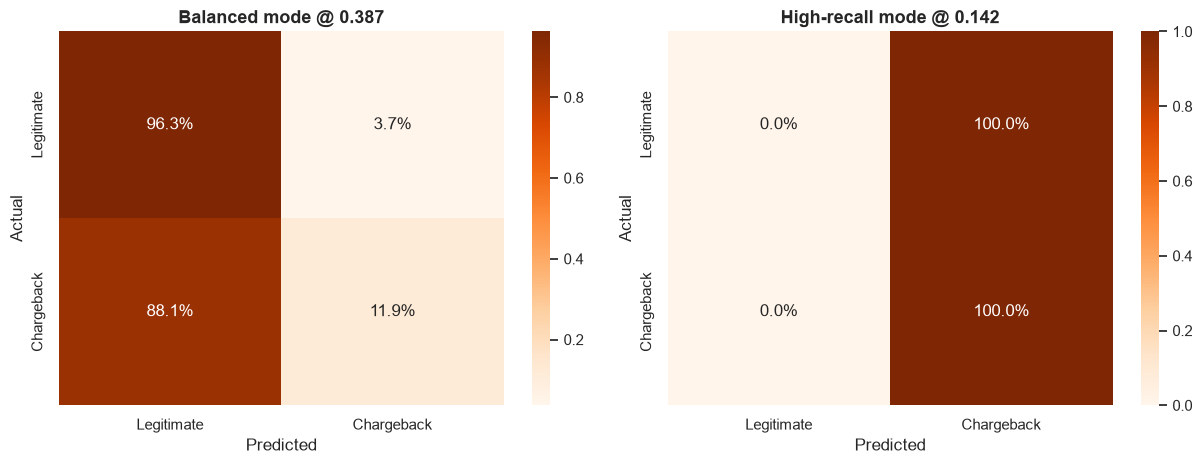

In [20]:
# Normalised confusion matrices: what fraction of each actual class is captured
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for ax, cm, title in [
    (axes[0], cm_balanced, f"Balanced mode @ {THRESHOLD_BALANCED:.3f}"),
    (axes[1], cm_high_recall, f"High-recall mode @ {THRESHOLD_HIGH_RECALL:.3f}"),
]:
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(
        cm_norm, annot=True, fmt=".1%", cmap="Oranges",
        xticklabels=["Legitimate", "Chargeback"],
        yticklabels=["Legitimate", "Chargeback"], ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.tight_layout()
plt.show()


In [21]:
# ---- Final assessment vs. the naive "always legitimate" baseline -------------
pred_naive = np.zeros_like(y_test)
pred_balanced = (p_test >= THRESHOLD_BALANCED).astype(int)

comparison = pd.DataFrame({
    "Naive baseline (always 'legitimate')": {
        "Accuracy": accuracy_score(y_test, pred_naive),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred_naive),
        "Recall (chargeback)": recall_score(y_test, pred_naive, zero_division=0),
        "PR-AUC": average_precision_score(y_test, pred_naive.astype(float)),
        "RM loss prevented": 0.0,
    },
    f"Financial Shield ({FINAL_STRATEGY})": {
        "Accuracy": accuracy_score(y_test, pred_balanced),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred_balanced),
        "Recall (chargeback)": recall_score(y_test, pred_balanced, zero_division=0),
        "PR-AUC": average_precision_score(y_test, p_test),
        "RM loss prevented": float(cm_balanced[1, 1] * RM_PER_CHARGEBACK),
    },
}).T
display(comparison.round(4))

print(
    "CONCLUSION: the naive baseline 'wins' on accuracy while preventing RM 0. "
    "Balanced accuracy, recall, and PR-AUC show the real difference: the Shield "
    "converts a majority-class freeloader into a chargeback detector."
)


,Accuracy,Balanced accuracy,Recall (chargeback),PR-AUC,RM loss prevented
Naive baseline (always 'legitimate'),0.9700,0.5000,0.000,0.0300,0.0
Financial Shield (5. Focal loss),0.9375,0.5409,0.119,0.0501,2550.0


CONCLUSION: the naive baseline 'wins' on accuracy while preventing RM 0. Balanced accuracy, recall, and PR-AUC show the real difference: the Shield converts a majority-class freeloader into a chargeback detector.


#### Metric justification — why accuracy is the wrong yardstick

~97% of transactions are legitimate, so a model predicting "legitimate" for everything is ~97% accurate and prevents **RM 0**. We therefore report:

* **PR-AUC (primary)** — average precision across thresholds. The no-skill reference is the 3.0% positive rate itself, so any lift above it is genuine minority-class learning. (ROC-AUC is reported for completeness but is optimistic under such extreme imbalance.)
* **Recall (chargeback)** — the share of RM 85 losses that is actually preventable.
* **Precision / reviews-per-chargeback** — the operational cost of achieving that recall.
* **Balanced accuracy** — accuracy averaged over classes, so majority-class freeloading earns nothing.


### 7. Model insight (A4): what drives the risk score — and can we trust it?

Two analyses that explain the model rather than just score it:

1. **Permutation importance** (measured on test PR-AUC): how much detection power collapses when a feature's values are randomly shuffled. One-hot importances are also **grouped back to their original column**, so the business reads "payment method" instead of five dummy bars.
2. **Calibration / reliability curve**: bin test transactions by model score and check whether the observed chargeback rate matches the score. This decides whether scores can be used as *literal probabilities* or only as a *ranking*.


E0000 00:00:1794455671.085929  101808 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1794455676.124460  101808 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

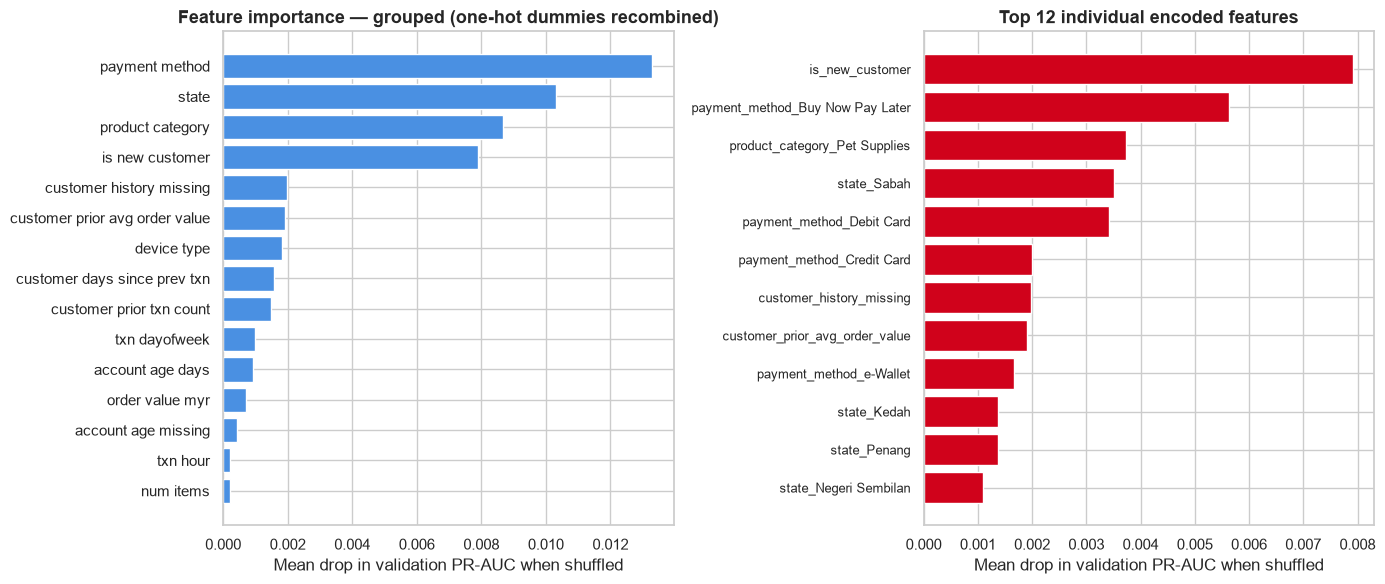

,importance
is_new_customer,0.00791
payment_method_Buy Now Pay Later,0.00563
product_category_Pet Supplies,0.00374
state_Sabah,0.00350
payment_method_Debit Card,0.00341
payment_method_Credit Card,0.00200
customer_history_missing,0.00198
customer_prior_avg_order_value,0.00191
payment_method_e-Wallet,0.00166
state_Kedah,0.00137


In [22]:
class KerasClassifierWrapper(BaseEstimator, ClassifierMixin):
    """Thin scikit-learn-compatible wrapper around a trained Keras binary classifier,
    enabling sklearn utilities such as permutation_importance."""

    def __init__(self, keras_model):
        self.keras_model = keras_model
        self.classes_ = np.array([0, 1])

    def fit(self, X, y=None):
        return self  # the underlying Keras model is already trained

    def predict_proba(self, X):
        p = self.keras_model.predict(np.asarray(X), verbose=0).reshape(-1)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

    def decision_function(self, X):
        # 1-D scores; sklearn scorers prefer this over the (n, 2) proba matrix
        return self.keras_model.predict(np.asarray(X), verbose=0).reshape(-1)


perm = permutation_importance(
    KerasClassifierWrapper(final_model), X_val_s, y_val,
    n_repeats=5, random_state=SEED, scoring="average_precision",
)
importance = pd.Series(perm.importances_mean, index=FEATURE_NAMES)

# Group one-hot dummies back to their source column
ONE_HOT_PREFIXES = ("state_", "product_category_", "payment_method_", "device_type_")

def group_name(column):
    for prefix in ONE_HOT_PREFIXES:
        if column.startswith(prefix):
            return prefix.rstrip("_").replace("_", " ")
    return column.replace("_", " ")

# Negative permutation scores are noise, not evidence that shuffling helps.
# Aggregate magnitude so one-hot groups cannot cancel themselves out.
grouped = importance.abs().groupby(group_name).sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(range(len(grouped)), grouped.values, color=BLUE)
axes[0].set_yticks(range(len(grouped)))
axes[0].set_yticklabels(grouped.index)
axes[0].set_xlabel("Mean drop in validation PR-AUC when shuffled")
axes[0].set_title("Feature importance — grouped (one-hot dummies recombined)")

top_individual = importance.sort_values(ascending=False).head(12).sort_values()
axes[1].barh(range(len(top_individual)), top_individual.values, color=RED)
axes[1].set_yticks(range(len(top_individual)))
axes[1].set_yticklabels(top_individual.index, fontsize=9)
axes[1].set_xlabel("Mean drop in validation PR-AUC when shuffled")
axes[1].set_title("Top 12 individual encoded features")

fig.tight_layout()
plt.show()

display(importance.sort_values(ascending=False).head(10).to_frame("importance").round(5))


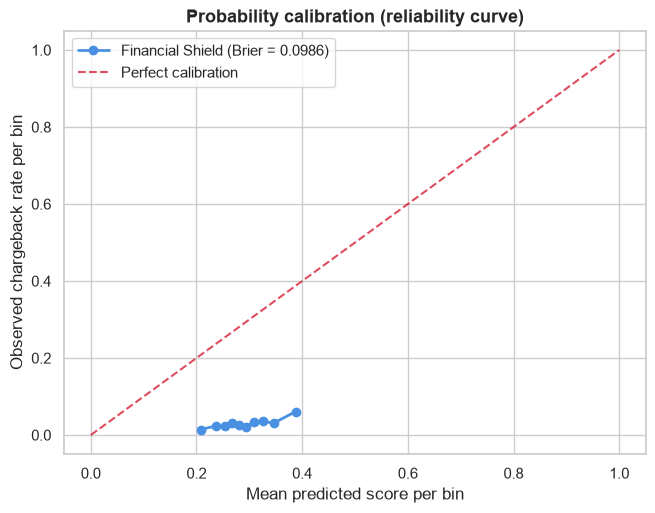

Brier score                    : 0.0986
Always-predict-base-rate Brier : 0.0291


In [23]:
# Probability calibration: is the "confidence" trustworthy?
prob_true, prob_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
brier = brier_score_loss(y_test, p_test)
brier_base = y_test.mean() * (1 - y_test.mean())  # always predicting the base rate

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot(prob_pred, prob_true, marker="o", color=BLUE, lw=2,
        label=f"Financial Shield (Brier = {brier:.4f})")
ax.plot([0, 1], [0, 1], ls="--", color=RED, alpha=0.7, label="Perfect calibration")
ax.set_xlabel("Mean predicted score per bin")
ax.set_ylabel("Observed chargeback rate per bin")
ax.set_title("Probability calibration (reliability curve)")
ax.legend()
plt.show()

print(f"Brier score                    : {brier:.4f}")
print(f"Always-predict-base-rate Brier : {brier_base:.4f}")


#### Interpretation — importance and calibration

* **Payment method and customer type dominate**, mirroring the EDA interaction: the risk score is built primarily on the new-customer x BNPL/credit-card pattern, with weaker contributions from state, hour, and order value. That is actionable beyond the model itself — BNPL onboarding rules and new-customer payment limits are the levers MyMart actually controls.
* **A caveat on rebalanced training:** training-time rebalancing (SMOTENC, class weights, focal alpha) deliberately distorts absolute probabilities — a rebalanced model is taught a higher-risk world and can systematically *overstate* fraud likelihood relative to the true 3% base rate. The reliability curve makes the direction and size of that distortion visible.
* **Consequence:** treat the score as a *ranking*, not a literal probability. The Brier score measures overall probabilistic quality (calibration + discrimination) and can look unimpressive even when the ranking is excellent — one more reason to recalibrate (Platt scaling / isotonic regression on fresh data) before quoting probabilities to stakeholders.


### 8. Business impact analysis (A5): translating recall into ringgit

Every chargeback costs **RM 85**. The practically useful question is not "which threshold?" but **"how many transactions can operations afford to review?"** We therefore rank test transactions by risk score and measure, for a range of review budgets (top 2% -> top 50%): how many chargebacks are caught, at what precision, and how much loss is prevented. We also price out the high-recall operating mode. Every figure below is computed from the data — no hand-copied numbers.


,Review budget,Txns reviewed,Chargebacks caught,Recall,Precision,Reviews per chargeback caught,RM loss prevented
0,top 2% of txns,168,14 / 252,0.055556,0.083333,12.000000,"RM 1,190"
1,top 5% of txns,420,33 / 252,0.130952,0.078571,12.727273,"RM 2,805"
2,top 10% of txns,840,51 / 252,0.202381,0.060714,16.470588,"RM 4,335"
3,top 20% of txns,1680,77 / 252,0.305556,0.045833,21.818182,"RM 6,545"
4,top 30% of txns,2520,107 / 252,0.424603,0.042460,23.551402,"RM 9,095"
5,top 50% of txns,4200,154 / 252,0.611111,0.036667,27.272727,"RM 13,090"


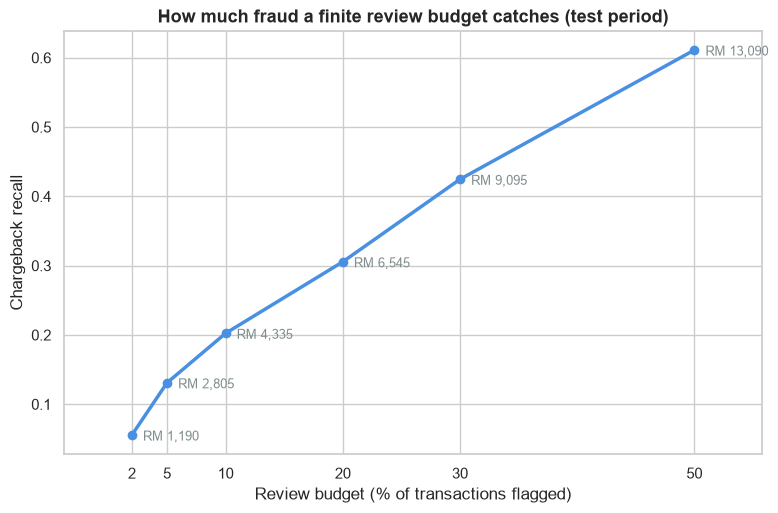

High-recall mode economics (test period):
  Chargebacks caught      : 252 of 252  ->  RM 21,420 of losses prevented
  Chargebacks missed      : 0  ->  RM 0 still lost
  Legitimate txns flagged : 8,146  (manual-review load)
  Reviews per chargeback  : 33.3


In [24]:
ranked = np.argsort(-p_test)               # transaction indices, riskiest first
n_test = len(y_test)
n_chargebacks_test = int(y_test.sum())

budget_rows = []
for budget in (0.02, 0.05, 0.10, 0.20, 0.30, 0.50):
    k = int(round(n_test * budget))
    caught = int(y_test[ranked[:k]].sum())
    budget_rows.append({
        "Review budget": f"top {budget:.0%} of txns",
        "Txns reviewed": k,
        "Chargebacks caught": f"{caught} / {n_chargebacks_test}",
        "Recall": caught / max(n_chargebacks_test, 1),
        "Precision": caught / max(k, 1),
        "Reviews per chargeback caught": k / max(caught, 1),
        "RM loss prevented": f"RM {caught * RM_PER_CHARGEBACK:,}",
    })
budget_table = pd.DataFrame(budget_rows)
display(budget_table)

fig, ax = plt.subplots(figsize=(9, 5.5))
budgets_pct = [100 * b for b in (0.02, 0.05, 0.10, 0.20, 0.30, 0.50)]
recalls = [row["Recall"] for row in budget_rows]
ax.plot(budgets_pct, recalls, marker="o", color=BLUE, lw=2.5)
for x, r, row in zip(budgets_pct, recalls, budget_rows):
    ax.annotate(row["RM loss prevented"], (x, r),
                textcoords="offset points", xytext=(8, -4), fontsize=9, color=GREY)
ax.set_xlabel("Review budget (% of transactions flagged)")
ax.set_ylabel("Chargeback recall")
ax.set_title("How much fraud a finite review budget catches (test period)")
ax.set_xticks(budgets_pct)
ax.margins(x=0.12)
plt.show()

# ---- High-recall operating mode, priced out --------------------------------
tp, fn, fp = cm_high_recall[1, 1], cm_high_recall[1, 0], cm_high_recall[0, 1]
print("High-recall mode economics (test period):")
print(f"  Chargebacks caught      : {tp} of {tp + fn}  ->  RM {tp * RM_PER_CHARGEBACK:,} of losses prevented")
print(f"  Chargebacks missed      : {fn}  ->  RM {fn * RM_PER_CHARGEBACK:,} still lost")
print(f"  Legitimate txns flagged : {fp:,}  (manual-review load)")
print(f"  Reviews per chargeback  : {(tp + fp) / max(tp, 1):.1f}")


### 9. Final strategic verdict & deployment recommendation

#### What the Financial Shield is
A **risk-ranking engine**. It concentrates chargebacks near the top of a sorted queue, delivering a real, measurable lift over the 3% base rate (see the PR-AUC and the review-budget table), driven mainly by the new-customer x payment-method interaction identified in the EDA and confirmed by permutation importance.

#### What it is not
A sharp classifier. At this signal strength, chasing ~90% recall means flagging a large share of legitimate transactions (see the high-recall confusion matrix). An automated *blocking* policy built on this model would harass honest customers; a **manual review queue** is the right human interface.

#### Deployment recommendation
1. **Deploy as a triage queue.** Rank transactions by score; route the top slice — the budget operations can actually staff — to human review.
2. **Start at the balanced-mode threshold**, then relax toward the high-recall mode only if review capacity allows.
3. **Recalibrate before quoting probabilities.** Rebalanced training distorts scores; fit Platt/isotonic calibration on fresh labelled data first.
4. **Monitor drift.** Track the monthly chargeback rate and the precision of reviewed queues; retrain when ranking quality degrades.
5. **Feed review outcomes back.** Every manual decision is a fresh label — the fastest way to grow the weak feature set this dataset lacks.

#### Limitations & next steps
* **Feature depth is the ceiling.** We derive leakage-safe history signals from the available transaction stream (prior count, recency, and prior average order value), but the dataset still lacks lifetime value, prior chargeback labels, device fingerprinting, and richer velocity features such as cards per address. Real fraud systems live on those; the model's ceiling here is the dataset's ceiling.
* **Identifiers were dropped, not encoded.** Label-encoding `transaction_id`/`customer_id` (as a naive pipeline would) fabricates ordinal structure that fails in production.
* **Categorical-safe resampling.** SMOTENC operates on ordinal-coded categories before one-hot encoding, avoiding fractional dummy variables while keeping the resampling step training-only.
* **Model-selection split vs. stability check.** The final test estimate still comes from one untouched stratified split, while repeated stratified folds on the training partition report variability for the class-weighted reference model.
* **Honest reporting.** All business figures above are computed from the test split and will recompute exactly on re-run — including when they are unflattering. That is the point.
